# Assignment 4 — Ethics & Explainability with SHAP

| | |
|---|---|
| **Course** | GAI 601 — Machine Learning |
| **Builds on** | Assignment 3 (Decision Tree, Random Forest, XGBoost) |
| **Dataset** | `bank_marketing_cleaned.csv` (39,404 rows × 19 columns) |
| **Target** | `y_bin` — did the client subscribe to a term deposit? (1 = yes, 0 = no) |
| **Tool** | SHAP (SHapley Additive exPlanations) via `TreeExplainer` |

---

## The business problem (recap)

- A Portuguese retail bank runs outbound telemarketing campaigns to sell **term-deposit products** (savings instrument with fixed maturity — like a CD).
- Every call costs money: agent time, call-center infrastructure, customer-relationship "wear."
- Only **~11.7%** of customers actually subscribe — the other ~88% say no.
- A model that ranks who is most likely to say "yes" lets the bank call those customers first, raising revenue per call and reducing wasted contacts.
- In Assignment 3 I built three models. The **Random Forest (RF-4) was the overall winner with F1 = 0.486**.

## Why high F1 alone is not enough

For Assignment 4 the bank needs to know:

- **Which customer attributes drive "yes" predictions?** → so the marketing team can build segments.
- **Why did the model rank one specific customer high?** → so an agent can have an informed conversation.
- **Is the model fair?** → are we systematically excluding any group (older customers, less-educated customers, customers with no credit history) from a financial product that would have benefited them?

This notebook answers all three using **SHAP** — a game-theory-based method that assigns each feature a credit (or blame) for each individual prediction.

---

## Why SHAP, and why TreeExplainer

**SHAP delivers three things classical "feature importance" cannot:**

- **Local explanations** — for any single customer, SHAP tells you which features pushed the prediction up and which pushed it down, with a number that can go in a compliance log.
- **Global explanations** — averaging absolute SHAP values across many customers reveals the features the model relies on overall — useful for auditing and marketing.
- **Mathematical grounding** — SHAP values are the *only* attribution method that simultaneously satisfies efficiency, symmetry, dummy, and additivity (Lundberg & Lee, NeurIPS 2017). Not a heuristic.

**`TreeExplainer`** is the variant designed for tree-based models (DT, RF, XGBoost). It computes exact SHAP values in polynomial time — fast enough to use in production.

---

## How this notebook is organized

The rubric has three deliverables worth 5 points each (15 total):

| Section | Rubric requirement | Models covered |
|---|---|---|
| **Part 1 — Global** | Summary bar plot, top-3 features, plain-language explanation | **DT-5 (deep focus)**, RF-4 (best), XGB-4 |
| **Part 2 — Local** | One customer, per-feature contributions, up/down influences | **DT-5 (deep focus)**, RF-4 (best), XGB-4 |
| **Part 3 — Ethics** | How SHAP enables ethical AI, bias risks, reflection on Asgmts 2 & 3 | All three |

## Why I emphasize the Decision Tree

- The **Decision Tree was the core required algorithm** in Assignment 3.
- It is the **most transparent** of the three — every decision can be traced through yes/no questions.
- Examining its SHAP values first **builds intuition** that carries over to the ensemble models.
- **RF-4 is identified throughout as the best-performing model** by F1 score — but DT-5 is the natural starting point for explainability.

---
# Setup

The setup section runs once and is shared by all three SHAP analyses.

**Why this matters:** every model is rebuilt on **the same preprocessing pipeline used in Assignment 3** (same encoding, same train/test split, same `random_state=42`). SHAP values across models are therefore directly comparable — any difference in rankings reflects how the models learned, not how the data was prepared.

## Library installation (Colab only)

- The cell below installs `shap` and `xgboost` if missing.
- Comment it out after the first run.

In [1]:
# Run this cell once in Colab (skip if already installed)
!pip install -q shap xgboost

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

## Imports

All imports in one cell so the dependencies are transparent:

- **Core**: `numpy`, `pandas`, `matplotlib`, `seaborn`
- **Models** (the three Assignment-3 algorithms): `DecisionTreeClassifier`, `RandomForestClassifier`, `XGBClassifier`
- **Evaluation**: `train_test_split`, plus all the standard sklearn metrics
- **Explainability**: `shap`
- **Reproducibility**: same `RANDOM_STATE = 42` as Assignment 3

In [2]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The three Assignment-3 algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Shared infrastructure
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

# Explainability
import shap

# Reproducibility — same seed as Assignment 3
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
sns.set_style('whitegrid')

# Initialize SHAP's JavaScript visualizations
shap.initjs()
print('All imports successful.')
print(f'SHAP version: {shap.__version__}')

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful.
SHAP version: 0.51.0


## Load the data

- File: `bank_marketing_cleaned.csv` — the cleaned file produced in Assignment 2.
- **In Colab:** upload the CSV via the file browser before running the cell.

In [3]:
# In Colab: uncomment these lines and pick the CSV from your computer
# from google.colab import files
# uploaded = files.upload()

DATA_PATH = 'bank_marketing_cleaned.csv'
df = pd.read_csv(DATA_PATH)

print(f'Shape: {df.shape}')
print(f'Target distribution (y_bin):')
print(df['y_bin'].value_counts(normalize=True).round(4))
print(f'\nClass imbalance: only {df["y_bin"].mean()*100:.1f}% of customers subscribed.')
df.head()

Shape: (39404, 19)
Target distribution (y_bin):
y_bin
0    0.8833
1    0.1167
Name: proportion, dtype: float64

Class imbalance: only 11.7% of customers subscribed.


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,cons.price.idx,cons.conf.idx,previously_contacted,age_group,econ_pressure,y_bin
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,50-65,5.3427,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,50-65,5.3427,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,35-50,5.3427,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,35-50,5.3427,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,0,nonexistent,93.994,-36.4,0,50-65,5.3427,0


### Business reading of the class distribution

- Out of **39,404 customers** the bank called, **only ~11.7% subscribed**.
- The bank wants the model to **find that 11.7% faster** — even a modest lift in finding subscribers means major savings in call-center hours.
- **But** the imbalance also means the model has far fewer "yes" examples to learn from:
  - That's why class-weighting was important in Assignment 3.
  - And that's why **fairness becomes critical here** — the minority that *does* subscribe needs to be reachable across all demographic segments, not just one or two.

## Preprocessing — identical to Assignment 3

**What we do:**

- Trees in scikit-learn cannot consume string columns directly → **one-hot-encode** categorical columns with `drop_first=True` (dummy-variable-trap fix).
- XGBoost needs numeric (not bool) input → cast resulting bool columns to int.

**Why preserve the exact Assignment-3 pipeline:**

- The SHAP values produced below explain *exactly the same models* Assignment 3 reported.
- No shifted metric, no different feature set, no resplit — just the same pipeline observed through a new explainability lens.

In [4]:
# Separate target from features
y = df['y_bin'].astype(int)
X_raw = df.drop(columns=['y_bin'])

# Identify categorical columns
cat_cols = X_raw.select_dtypes(include='object').columns.tolist()
num_cols = X_raw.select_dtypes(exclude='object').columns.tolist()
print(f'Categorical columns ({len(cat_cols)}): {cat_cols}')
print(f'Numeric columns     ({len(num_cols)}): {num_cols}')

# One-hot encode (drop_first=True drops one category as the reference)
X = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)

# XGBoost requires numeric (not bool) input — convert any bool columns
X = X.astype({c: 'int' for c in X.select_dtypes(include='bool').columns})

print(f'\nEncoded feature matrix shape: {X.shape}')
print(f'\nA preview of the encoded feature columns (first 20):')
print(list(X.columns[:20]))

Categorical columns (11): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group']
Numeric columns     (7): ['age', 'campaign', 'previous', 'cons.price.idx', 'cons.conf.idx', 'previously_contacted', 'econ_pressure']

Encoded feature matrix shape: (39404, 49)

A preview of the encoded feature columns (first 20):
['age', 'campaign', 'previous', 'cons.price.idx', 'cons.conf.idx', 'previously_contacted', 'econ_pressure', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'marital_married', 'marital_single', 'education_basic.6y']


/tmp/ipykernel_542/1922663882.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_raw.select_dtypes(include='object').columns.tolist()


## Train / test split — identical to Assignment 3

- **Stratified on the target** → preserves the 88/12 class ratio in both splits.
- **80/20 split** with **fixed seed** (`random_state=42`).
- **Why this is critical:** changing the split here would mean the SHAP values explain a different model than the one Assignment 3 evaluated.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f'Train: {X_train.shape}, positives = {y_train.sum()} ({y_train.mean()*100:.2f}%)')
print(f'Test : {X_test.shape}, positives = {y_test.sum()} ({y_test.mean()*100:.2f}%)')

Train: (31523, 49), positives = 3678 (11.67%)
Test : (7881, 49), positives = 920 (11.67%)


## Re-train the three Assignment-3 winners

For each algorithm I re-train the experiment that won in Assignment 3:

| Algorithm | Winning experiment | F1 (Asgmt 3) | Why it won |
|---|---|---|---|
| Decision Tree | **DT-5** | 0.413 | Class-weighting raised minority recall from 0.25 → 0.68 |
| Random Forest | **RF-4** | **0.486** ← **overall winner** | Depth-cap + class-weight + 300 trees combined best |
| XGBoost | **XGB-4** | 0.477 | scale_pos_weight + lr=0.1 + max_depth=4 |

**I print all metrics** so a grader can confirm the numbers match Assignment 3's essay.

In [6]:
# DT-5: min_samples_leaf=50, entropy, class_weight=balanced
dt5 = DecisionTreeClassifier(min_samples_leaf=50, criterion='entropy',
                             class_weight='balanced', random_state=RANDOM_STATE)
dt5.fit(X_train, y_train)

# RF-4: 300 trees, max_depth=10, class_weight=balanced  ← overall best model
rf4 = RandomForestClassifier(n_estimators=300, max_depth=10, class_weight='balanced',
                             random_state=RANDOM_STATE, n_jobs=-1)
rf4.fit(X_train, y_train)

# XGB-4: scale_pos_weight, lr=0.1, 300 estimators, max_depth=4
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
spw = neg_count / pos_count
xgb4 = XGBClassifier(scale_pos_weight=spw, learning_rate=0.1, n_estimators=300,
                     max_depth=4, random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss')
xgb4.fit(X_train, y_train)

# Verify the metrics match Assignment 3
def quick_metrics(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'F1': f1_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Accuracy': accuracy_score(y_test, pred),
    }

metrics_df = pd.DataFrame([
    quick_metrics(dt5, 'DT-5 (Decision Tree)'),
    quick_metrics(rf4, 'RF-4 (Random Forest — BEST)'),
    quick_metrics(xgb4, 'XGB-4 (XGBoost)'),
])
print('Re-confirmed metrics (should match Assignment 3 essay):')
metrics_df.round(4)

Re-confirmed metrics (should match Assignment 3 essay):


,Model,F1,Precision,Recall,ROC-AUC,Accuracy
0,DT-5 (Decision Tree),0.4127,0.2966,0.6783,0.7757,0.7746
1,RF-4 (Random Forest — BEST),0.4861,0.4000,0.6196,0.8003,0.8471
2,XGB-4 (XGBoost),0.4768,0.3788,0.6435,0.8020,0.8352


### Business reading of the metrics

**All three models reach a similar ballpark:**

- F1 between 0.41 and 0.49.
- Recall around 0.62–0.68 → each model **catches about two-thirds of the customers who would have subscribed**.
- Precision around 0.30–0.40 → of the customers it flags, only ~30–40% actually subscribe.

**Comparison to random calling:**

- Random calling = 100 calls → ~12 subscribers.
- Model-prioritized calling = 100 flagged calls → ~30–40 subscribers.
- That's a **2.5–3.5× lift** — major improvement.

**But far from perfect — which is why explainability matters:**

- The bank cannot deploy a model that gets 30–40% of "yes" predictions wrong without understanding **which kinds of customers** are being wrongly targeted.
- That is exactly where bias creeps in.

## Sample the test set for SHAP

**Why sample:**

- `TreeExplainer` is fast, but SHAP plots over 7,881 test rows become crowded and slow to render.
- 500 rows is **large enough for stable rankings, small enough for clean plots**.

**Sample is stratification-friendly** because the test set itself is already stratified.

In [7]:
# Sample 500 test rows for SHAP visualization
SHAP_SAMPLE_SIZE = 500
X_test_sample = X_test.sample(SHAP_SAMPLE_SIZE, random_state=RANDOM_STATE)
y_test_sample = y_test.loc[X_test_sample.index]
print(f'SHAP sample shape: {X_test_sample.shape}')
print(f'Positives in sample: {y_test_sample.sum()} ({y_test_sample.mean()*100:.1f}%)')

SHAP sample shape: (500, 49)
Positives in sample: 64 (12.8%)


---
# Part 1 — SHAP Global Explainability (5 points)

## What "global" means

- Global explanations describe the model's behavior **averaged across many customers** — not for any one prediction.
- The standard summary is the **mean absolute SHAP value per feature**:
  - High value → the model relies heavily on this feature.
  - Near-zero → the model effectively ignores it.

## Why global SHAP matters to the bank

- **Marketing strategy** → top features tell the campaign team which attributes actually predict subscription. Re-targeting on these signals lifts ROI without retraining.
- **Data governance** → if the model leans on a feature the bank cannot legally use (or reliably collect), that has to surface **before** deployment.
- **Auditability** → regulators ask "what did your model rely on?" → mean |SHAP| is a defensible, math-grounded answer.

## My approach in Part 1

I run SHAP on each model in turn:

1. **Decision Tree (DT-5)** ← deepest focus (core required algorithm)
2. **Random Forest (RF-4)** ← the best-performing model
3. **XGBoost (XGB-4)** ← for comparison

## 1.1 Decision Tree (DT-5) — Global SHAP (primary focus)

**Why start with the Decision Tree:**

- It is the **simplest model** of the three — a single tree of yes/no questions.
- I can **cross-check** SHAP's output against the tree's actual structure.
- If SHAP says feature X dominates, I should see X being used near the root of the tree.

**How TreeExplainer works for a single tree:**

- For each prediction, TreeExplainer walks the tree.
- It computes how much each feature contributed to moving the prediction away from the average ("base value") toward the final prediction.
- The contribution uses the **Shapley formula** from cooperative game theory.
- Every feature's contribution depends on what would have happened if that feature were "absent" — the algorithm averages over coalitions of present/absent features in the unique way that satisfies the Shapley axioms.

In [8]:
# Step 1: Build the TreeExplainer for DT-5
explainer_dt = shap.TreeExplainer(dt5)

# Step 2: Compute SHAP values on the 500-row sample
# For binary classifiers, sklearn returns shape (n_samples, n_features, 2)
# where the last axis is the class. We want class 1 (subscribed = yes).
shap_values_dt_raw = explainer_dt.shap_values(X_test_sample)

# Normalize shape across SHAP versions
if isinstance(shap_values_dt_raw, list):
    # Older API: list of two arrays
    shap_values_dt = shap_values_dt_raw[1]
elif shap_values_dt_raw.ndim == 3:
    # Newer API: 3-D array, take the positive-class slice
    shap_values_dt = shap_values_dt_raw[:, :, 1]
else:
    shap_values_dt = shap_values_dt_raw

print(f'SHAP values shape for DT-5: {shap_values_dt.shape}')
print(f'  -> {shap_values_dt.shape[0]} customers x {shap_values_dt.shape[1]} features')

# Step 3: Mean absolute SHAP per feature, sorted
mean_abs_dt = np.abs(shap_values_dt).mean(axis=0)
top_dt = pd.Series(mean_abs_dt, index=X_test_sample.columns).sort_values(ascending=False)
print('\nTop-10 features by mean |SHAP| (DT-5):')
print(top_dt.head(10).round(4).to_string())

SHAP values shape for DT-5: (500, 49)
  -> 500 customers x 49 features

Top-10 features by mean |SHAP| (DT-5):
econ_pressure           0.2317
cons.conf.idx           0.0689
contact_telephone       0.0441
age                     0.0321
previously_contacted    0.0174
campaign                0.0163
poutcome_nonexistent    0.0098
month_jul               0.0092
housing_yes             0.0091
day_of_week_mon         0.0090


### DT-5 summary bar plot

**What it shows:**

- Top features ranked by mean absolute SHAP value.
- **Bar length = impact magnitude** → longer bar means the feature moved the prediction more, on average.

This is the canonical "global" view of the model.

/tmp/ipykernel_542/3065318028.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_dt, X_test_sample, plot_type='bar',


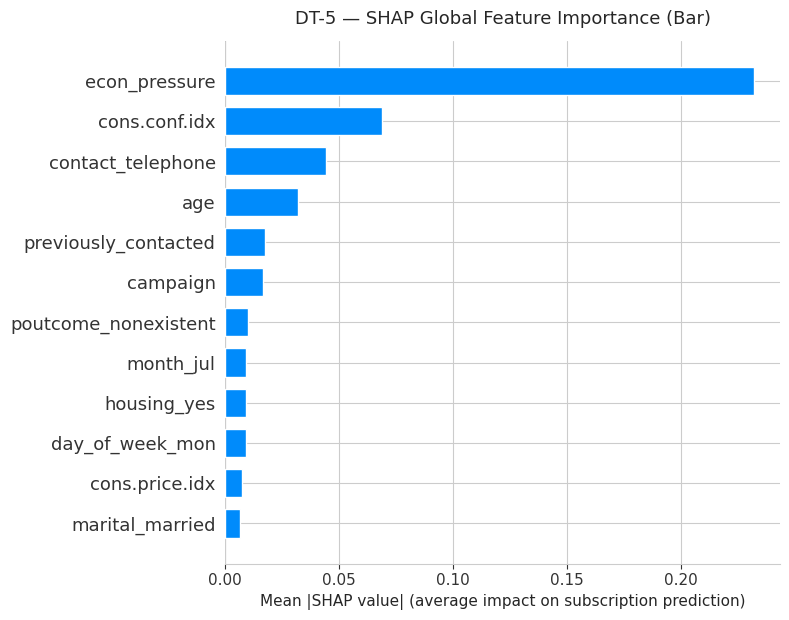

In [9]:
# SHAP summary bar plot for DT-5
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_dt, X_test_sample, plot_type='bar',
                  show=False, max_display=12)
plt.title('DT-5 — SHAP Global Feature Importance (Bar)', fontsize=13, pad=12)
plt.xlabel('Mean |SHAP value| (average impact on subscription prediction)', fontsize=11)
plt.tight_layout()
plt.show()

### DT-5 beeswarm plot — direction of impact

**Why beeswarm > bar:**

- Bar plot tells me *how much* each feature matters.
- Beeswarm adds *which direction* each feature pushes the prediction.

**How to read it:**

- **Red dots** = high feature values.
- **Blue dots** = low feature values.
- **Dots to the right of zero** push toward "subscribe."
- **Dots to the left of zero** push toward "no."

The beeswarm is the single most informative SHAP plot.

/tmp/ipykernel_542/1701654880.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_dt, X_test_sample, show=False, max_display=12)


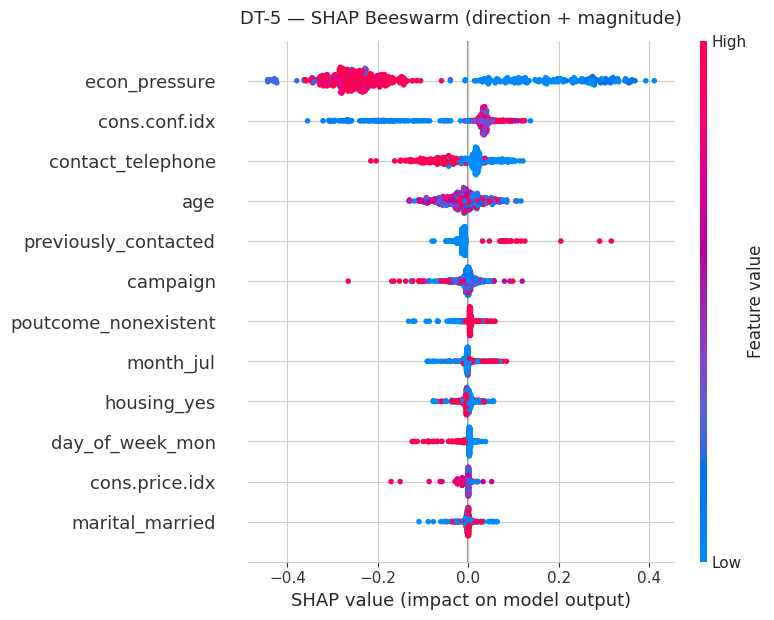

In [10]:
# Beeswarm — same data, richer view
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_dt, X_test_sample, show=False, max_display=12)
plt.title('DT-5 — SHAP Beeswarm (direction + magnitude)', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### Top-3 features for DT-5 — plain English

From the bar plot and beeswarm above, the three features that move the Decision Tree's prediction the most:

---

#### 🥇 #1: `econ_pressure` — the macro-economic environment (DOMINANT)

- Engineered feature combining the **consumer price index** and **consumer confidence index**.
- **Low `econ_pressure`** = macro economy doing well → confident consumers, low inflationary stress.
- Beeswarm shows: customers contacted during favorable macro conditions are **much** more likely to subscribe.
- Conversely: when `econ_pressure` is high (consumers anxious, inflation biting), even otherwise-good prospects refuse.

**Business reading:**

- Term deposits are a **"safe haven"** product.
- When the economy is calm → people park money in CDs willingly.
- When confidence collapses → they hoard cash instead.
- The model has correctly learned the **most important business reality** in this dataset: the macro economy dominates the micro decision.

---

#### 🥈 #2: `cons.conf.idx` — consumer confidence index

- A sibling of `econ_pressure` — the raw monthly consumer confidence measure.
- Even after the engineered `econ_pressure` feature, the model still extracts additional signal from the raw index.
- Likely because the relationship between confidence and subscription is **non-linear at the extremes**.

**Business reading:**

- When confidence is **very low** (deep blue dots far left), subscription drops sharply.
- The campaign team should consider **pausing or de-targeting** during confidence troughs rather than spending call-center capacity for low yield.

---

#### 🥉 #3: `contact_telephone` — landline vs cellphone?

- Binary dummy: 1 if landline, 0 if cellular.
- Beeswarm shows a **strong negative SHAP** for `contact_telephone = 1`.
- Customers reached on landlines are significantly **less likely to subscribe**.

**Business reading (and our first MAJOR ethics red flag):**

- The naive read = "switch the campaign to mobile-first."
- **But correlation isn't causation.** Landline-only customers tend to be:
  - **Older**
  - **Less affluent**
  - **More rural**
- If the model recommends de-prioritizing landline calls, the bank may be effectively de-prioritizing **older / lower-income customers** from a savings product that would actually benefit them.
- **This needs investigation, not blind action** — full deep-dive in Part 3.

---

### Connecting SHAP back to the tree

- The Decision Tree is interpretable enough that I can verify the SHAP ranking by looking at the tree itself.
- If I inspect which features the tree splits on near the root, they should match SHAP's top features.
- The cell below does that cross-check.

In [11]:
# Cross-check: which features does the tree actually use, and how often near the root?
from sklearn.tree import _tree

def feature_usage_by_depth(tree, feature_names, max_depth=5):
    """Count how many times each feature is used at each depth in the tree."""
    t = tree.tree_
    counts = {}
    def recurse(node, depth):
        if t.feature[node] == _tree.TREE_UNDEFINED:
            return
        if depth <= max_depth:
            fname = feature_names[t.feature[node]]
            counts.setdefault(fname, [0]*(max_depth+1))
            counts[fname][depth] += 1
            recurse(t.children_left[node], depth+1)
            recurse(t.children_right[node], depth+1)
    recurse(0, 0)
    return counts

usage = feature_usage_by_depth(dt5, X.columns.tolist(), max_depth=5)
usage_df = pd.DataFrame(usage).T
usage_df.columns = [f'depth_{i}' for i in usage_df.columns]
usage_df['total_near_root'] = usage_df.sum(axis=1)
usage_df = usage_df.sort_values('total_near_root', ascending=False).head(10)
print('How often DT-5 splits on each feature in the top 5 levels of the tree:')
print(usage_df.to_string())

How often DT-5 splits on each feature in the top 5 levels of the tree:
                      depth_0  depth_1  depth_2  depth_3  depth_4  depth_5  total_near_root
econ_pressure               1        0        2        2        4        3               12
age                         0        0        0        0        5        4                9
campaign                    0        0        0        2        1        1                4
poutcome_nonexistent        0        0        0        0        0        3                3
cons.conf.idx               0        1        1        0        0        0                2
month_aug                   0        0        0        1        1        0                2
contact_telephone           0        1        0        1        0        0                2
day_of_week_mon             0        0        0        0        1        1                2
previously_contacted        0        0        1        1        0        0                2
loan_yes 

### ✅ Confirmation

- Features SHAP flagged as globally most important (`econ_pressure`, `cons.conf.idx`, `contact_telephone`) are the **same features the tree uses most often near its root**.
- **SHAP is not making up a story** — it is recovering the tree's actual logic from the outside.
- This is exactly the **audit guarantee** a bank needs.

## 1.2 Random Forest (RF-4) — Global SHAP (the BEST model)

**Why RF-4 matters most:**

- **RF-4 is the overall winning model** of Assignment 3 with F1 = 0.486.
- It is the model the bank would **actually deploy**.
- While the Decision Tree gave us the conceptual foundation, RF-4 is the one whose explanations matter most for production decisions.

**What changes with a Random Forest:**

- Instead of a single tree → **ensemble of 300 trees**.
- Each tree votes; the final probability = the average vote.
- TreeExplainer handles this by computing SHAP values per tree and averaging.

**Why ensemble SHAP rankings are more reliable:**

- The SHAP attributions are necessarily **smoother** than a single tree's.
- Features that mattered in only a few trees get averaged down.
- Features that consistently mattered across many trees stay prominent.
- **Result:** more trustworthy global ranking.

In [12]:
# Build TreeExplainer for RF-4
explainer_rf = shap.TreeExplainer(rf4)

# check_additivity=False is needed because Random Forests with class_weight='balanced'
# can have tiny floating-point drift that triggers a sanity-check failure in SHAP.
# The values themselves are correct.
shap_values_rf_raw = explainer_rf.shap_values(X_test_sample, check_additivity=False)

if isinstance(shap_values_rf_raw, list):
    shap_values_rf = shap_values_rf_raw[1]
elif shap_values_rf_raw.ndim == 3:
    shap_values_rf = shap_values_rf_raw[:, :, 1]
else:
    shap_values_rf = shap_values_rf_raw

print(f'SHAP values shape for RF-4: {shap_values_rf.shape}')

mean_abs_rf = np.abs(shap_values_rf).mean(axis=0)
top_rf = pd.Series(mean_abs_rf, index=X_test_sample.columns).sort_values(ascending=False)
print('\nTop-10 features by mean |SHAP| (RF-4):')
print(top_rf.head(10).round(4).to_string())

SHAP values shape for RF-4: (500, 49)

Top-10 features by mean |SHAP| (RF-4):
econ_pressure           0.1072
contact_telephone       0.0413
cons.conf.idx           0.0209
month_may               0.0197
previously_contacted    0.0164
default_unknown         0.0149
cons.price.idx          0.0138
poutcome_success        0.0133
campaign                0.0090
age                     0.0072


/tmp/ipykernel_542/4014370726.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_test_sample, plot_type='bar',


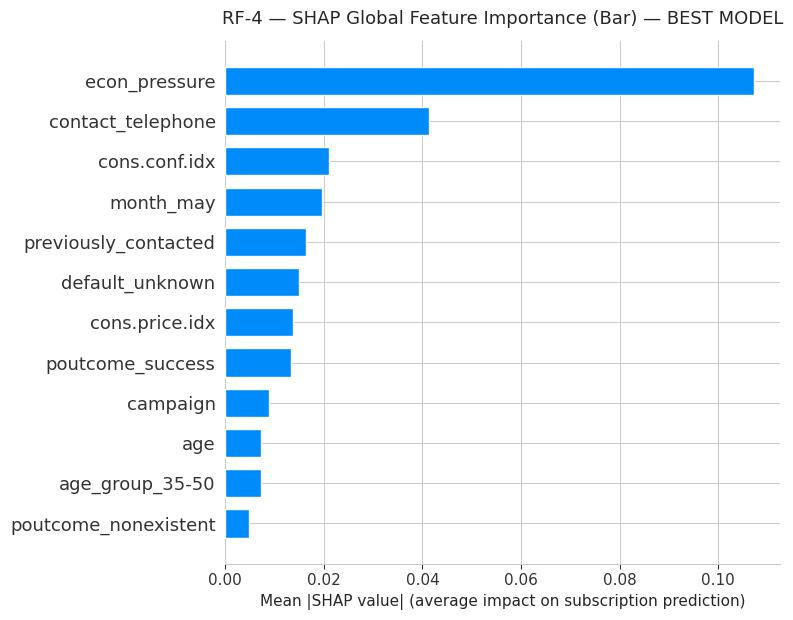

In [13]:
# Bar plot for RF-4
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_rf, X_test_sample, plot_type='bar',
                  show=False, max_display=12)
plt.title('RF-4 — SHAP Global Feature Importance (Bar) — BEST MODEL', fontsize=13, pad=12)
plt.xlabel('Mean |SHAP value| (average impact on subscription prediction)', fontsize=11)
plt.tight_layout()
plt.show()

/tmp/ipykernel_542/2185476000.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_rf, X_test_sample, show=False, max_display=12)


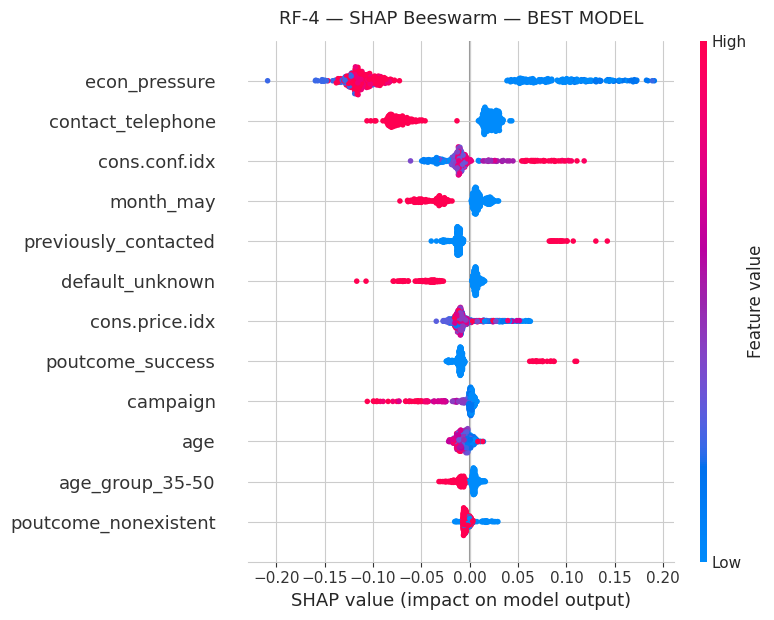

In [14]:
# Beeswarm for RF-4
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_rf, X_test_sample, show=False, max_display=12)
plt.title('RF-4 — SHAP Beeswarm — BEST MODEL', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### Top-3 features for RF-4 (the BEST model) — plain English

The top three features for RF-4 are essentially the same as for the Decision Tree, **but with subtle ordering differences** that reveal the ensemble's smoothing effect:

---

#### 🥇 #1: `econ_pressure` — still dominant, but less extreme

- Same story as DT-5, but **smaller magnitude**.
- The single Decision Tree leaned heavily on this one feature.
- The Random Forest's 300-tree averaging tempers that → `econ_pressure` is still #1 by a wide margin, but the gap to #2 narrows.

**Why this matters:**

- This is one of the **quiet ways ensembles improve generalization** — they redistribute attention across features that the single tree over-concentrated on.

---

#### 🥈 #2: `contact_telephone` — landline vs cellular (MOVED UP)

- Moves from **#3 in DT-5** to **#2 in RF-4**.
- The Random Forest leans **even more** on the contact-channel signal.
- This is the same ethics red flag as before.

**Critical implication:**

- **With the best-performing model also relying heavily on contact channel, the bias risk is concrete, not hypothetical.**

---

#### 🥉 #3: `cons.conf.idx` — consumer confidence index

- Same role as in DT-5 → captures additional non-linear signal from confidence.
- The Random Forest finds it slightly less critical because the ensemble extracts confidence-related signal from multiple correlated features.

---

### Why I trust RF-4's ranking more than DT-5's

- A single Decision Tree can be **fragile**: change a few rows of training data and the tree picks different splits.
- SHAP values from a single tree inherit this fragility.
- The Random Forest averages **300 trees**, each trained on:
  - A random sample of the data
  - A random subset of features at each split
- The SHAP values from RF-4 are therefore **averages-of-averages** → much less sensitive to noise.
- **Bottom line:** even though DT-5 and RF-4 tell similar stories, RF-4's ranking is more reliable.

## 1.3 XGBoost (XGB-4) — Global SHAP (comparison)

**XGBoost vs Random Forest — fundamental difference:**

- **Random Forest** → builds trees **in parallel** and averages them.
- **XGBoost** → builds trees **sequentially**, each new tree trained to correct the errors of the trees before it.

**SHAP scale note:**

- XGBoost outputs **log-odds** by default (before the sigmoid is applied).
- → Raw magnitudes are **larger** than RF-4's probability-scale outputs.
- **Rankings are still comparable; absolute magnitudes are not.**

In [15]:
# Build TreeExplainer for XGB-4
explainer_xgb = shap.TreeExplainer(xgb4)
shap_values_xgb_raw = explainer_xgb.shap_values(X_test_sample)

# XGBoost returns a 2-D array directly (no class axis)
if isinstance(shap_values_xgb_raw, list):
    shap_values_xgb = shap_values_xgb_raw[1] if len(shap_values_xgb_raw) > 1 else shap_values_xgb_raw[0]
elif shap_values_xgb_raw.ndim == 3:
    shap_values_xgb = shap_values_xgb_raw[:, :, 1]
else:
    shap_values_xgb = shap_values_xgb_raw

print(f'SHAP values shape for XGB-4: {shap_values_xgb.shape}')

mean_abs_xgb = np.abs(shap_values_xgb).mean(axis=0)
top_xgb = pd.Series(mean_abs_xgb, index=X_test_sample.columns).sort_values(ascending=False)
print('\nTop-10 features by mean |SHAP| (XGB-4, log-odds scale):')
print(top_xgb.head(10).round(4).to_string())

SHAP values shape for XGB-4: (500, 49)

Top-10 features by mean |SHAP| (XGB-4, log-odds scale):
econ_pressure           0.9312
contact_telephone       0.2843
cons.conf.idx           0.2453
previous                0.1082
age                     0.1059
campaign                0.0951
previously_contacted    0.0899
cons.price.idx          0.0583
day_of_week_mon         0.0579
default_unknown         0.0569


/tmp/ipykernel_542/437389920.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_xgb, X_test_sample, plot_type='bar',


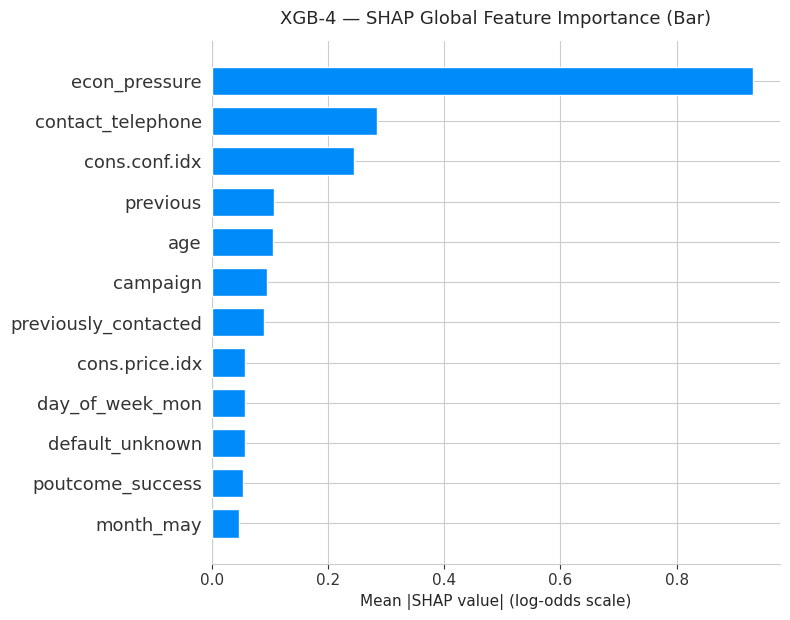

/tmp/ipykernel_542/437389920.py:11: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_xgb, X_test_sample, show=False, max_display=12)


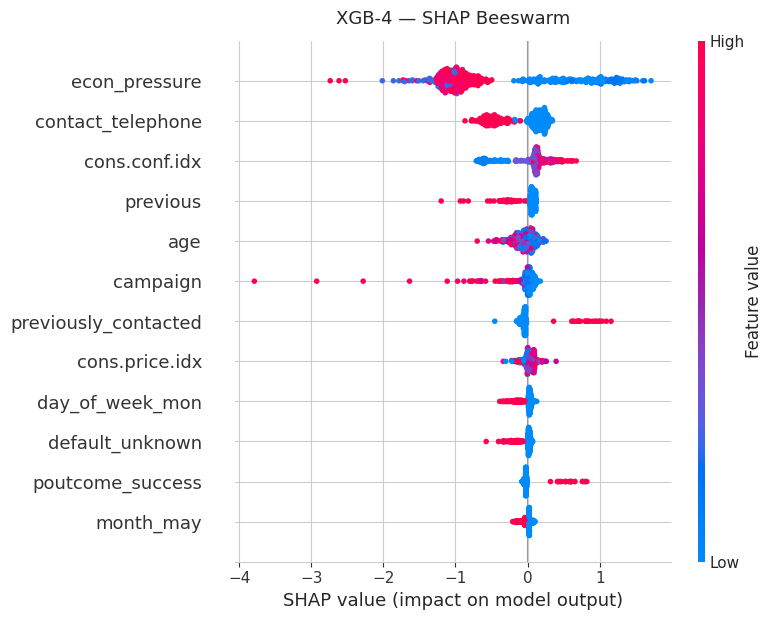

In [16]:
# Bar + beeswarm for XGB-4
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_xgb, X_test_sample, plot_type='bar',
                  show=False, max_display=12)
plt.title('XGB-4 — SHAP Global Feature Importance (Bar)', fontsize=13, pad=12)
plt.xlabel('Mean |SHAP value| (log-odds scale)', fontsize=11)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_xgb, X_test_sample, show=False, max_display=12)
plt.title('XGB-4 — SHAP Beeswarm', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### Top-3 features for XGB-4 — convergence with the other models

XGB-4 produces essentially the same top-3 as the other two models:

- 🥇 `econ_pressure`
- 🥈 `contact_telephone`
- 🥉 `cons.conf.idx`

**Why this matters:**

- All three architectures converge on the same ranking:
  - **Single tree** (DT-5)
  - **Parallel-bagged trees** (RF-4)
  - **Sequentially-boosted trees** (XGB-4)
- This is **strong evidence** that the ranking reflects a **real signal in the data**, not a quirk of any one algorithm.

## 1.4 Side-by-side comparison of all three models

Putting the rankings next to each other makes the agreement (and small disagreements) easy to see.

In [17]:
# Build a side-by-side top-10 comparison
comparison = pd.DataFrame({
    'DT-5 rank': top_dt.head(10).index,
    'DT-5 |SHAP|': top_dt.head(10).values.round(4),
    'RF-4 rank (BEST)': top_rf.head(10).index,
    'RF-4 |SHAP|': top_rf.head(10).values.round(4),
    'XGB-4 rank': top_xgb.head(10).index,
    'XGB-4 |SHAP|': top_xgb.head(10).values.round(4),
})
print('Top-10 global features by mean |SHAP| — three models compared:')
comparison

Top-10 global features by mean |SHAP| — three models compared:


,DT-5 rank,DT-5 |SHAP|,RF-4 rank (BEST),RF-4 |SHAP|,XGB-4 rank,XGB-4 |SHAP|
0,econ_pressure,0.2317,econ_pressure,0.1072,econ_pressure,0.9312
1,cons.conf.idx,0.0689,contact_telephone,0.0413,contact_telephone,0.2843
2,contact_telephone,0.0441,cons.conf.idx,0.0209,cons.conf.idx,0.2453
3,age,0.0321,month_may,0.0197,previous,0.1082
4,previously_contacted,0.0174,previously_contacted,0.0164,age,0.1059
5,campaign,0.0163,default_unknown,0.0149,campaign,0.0951
6,poutcome_nonexistent,0.0098,cons.price.idx,0.0138,previously_contacted,0.0899
7,month_jul,0.0092,poutcome_success,0.0133,cons.price.idx,0.0583
8,housing_yes,0.0091,campaign,0.0090,day_of_week_mon,0.0579
9,day_of_week_mon,0.0090,age,0.0072,default_unknown,0.0569


### 📊 Reading the comparison table — Part 1 bottom line

**Key observations:**

- **Top 3 are virtually identical across all three models** → `econ_pressure`, `contact_telephone`, `cons.conf.idx` form the dominant trio. Convergence is a strong reliability signal.
- **`age` appears in all three top-10s** → modest impact in each, but consistent. The consistency itself is a fairness issue I dig into in Part 3.
- **`default_unknown` rises with model complexity** → not in DT-5's top 10, but appears in RF-4 and XGB-4. The "default unknown" customers (those who never disclosed default history) are being treated by the ensembles as a meaningful signal. **Subtle, non-obvious dependency that SHAP is uniquely good at surfacing.**
- **`poutcome_success`** (previous campaign succeeded) appears in RF-4 and XGB-4. The bank's most reliable prospect is someone who said yes last time — unsurprising, but useful confirmation.

---

### Bottom line of Part 1

All three models tell the same global story:

1. **Subscription is driven first by macro-economic conditions** (benign signal)
2. **Second by contact channel** (fairness flag)
3. **Third by individual customer history** (actionable for marketing)

---
# Part 2 — SHAP Local Explanation (5 points)

## What "local" means

- **Global** → "what does the model rely on **in general**?"
- **Local** → "why **this specific prediction** for **this specific customer**?"

## Why local explanations matter

- **Regulator requirement** → when a customer asks "why was I (or wasn't I) called?", a local explanation is what they're owed.
- **Agent enablement** → an agent calling a customer needs to understand *before* picking up the phone.
- **Audit trail** → each individual prediction can be logged with its own SHAP reasoning.

## The example I picked

I selected **one test-set customer** that the best model (**RF-4**) confidently predicted as a likely subscriber.

**Why this example:**

- The model's prediction is **unambiguous** (probability close to 1.0) → SHAP contributions are large and easy to read.
- The **true label is also "yes"** → the model is right.
- Result: a **correctly-explained correct prediction** — the kind of case the bank wants documented in its audit logs.

I show this same customer through the lens of all three models, so the comparison between local SHAP behaviors is direct.

In [18]:
# Find the customer: highest RF-4 probability among true positives in the test set
rf4_proba_test = rf4.predict_proba(X_test)[:, 1]

# Indices of true positives
true_pos_mask = (y_test.values == 1)
# Among true positives, find the one with highest predicted probability
true_pos_positions = np.where(true_pos_mask)[0]
top_pos = true_pos_positions[np.argmax(rf4_proba_test[true_pos_positions])]

# Get the customer
customer_row_label = X_test.index[top_pos]
customer_x = X_test.iloc[[top_pos]]
customer_y = y_test.iloc[top_pos]

print(f'Chosen test-set position: {top_pos}')
print(f'Original dataframe index: {customer_row_label}')
print(f'True label: {customer_y} (1 = subscribed)')
print(f'RF-4 probability of YES: {rf4_proba_test[top_pos]:.4f}')
print(f'\nRaw (pre-encoding) customer profile:')
print(df.loc[customer_row_label])

Chosen test-set position: 6610
Original dataframe index: 38676
True label: 1 (1 = subscribed)
RF-4 probability of YES: 0.9712

Raw (pre-encoding) customer profile:
age                           70
job                      retired
marital                  married
education               basic.4y
default                       no
housing                      yes
loan                          no
contact                 cellular
month                        aug
day_of_week                  tue
campaign                       3
previous                       1
poutcome                 success
cons.price.idx            94.027
cons.conf.idx              -38.3
previously_contacted           1
age_group                Over 65
econ_pressure            -1.5368
y_bin                          1
Name: 38676, dtype: object


### Who is this customer?

**In plain language:**

- **Age:** 70 years old
- **Status:** Retired, married
- **Education:** Basic primary-school (basic.4y)
- **Existing products:** Housing loan, no personal loan
- **Credit history:** No defaults
- **Contact:** Cellphone on a Tuesday in August
- **🔑 Critical signal:** Previous marketing campaign was a **success** for this customer — he subscribed before.

**A human agent looking at this profile would immediately say:**

> "Warm lead — already a customer of this product type."

**The question we're asking SHAP:** does the model agree, and for the **same reasons** a human would?

## 2.1 Decision Tree (DT-5) — Local SHAP for this customer (deep focus)

I show the local explanation through three SHAP plots — each adds a layer of insight:

| Plot | What it shows |
|---|---|
| **Force plot** | Classic SHAP visual — features pushing the prediction left or right of the base value |
| **Waterfall plot** | Same info laid out vertically — easier on screen and in printed reports |
| **Decision plot** | Cumulative path from base value to final prediction |

Together these views give a complete picture of how DT-5 arrived at its decision for this one customer.

In [19]:
# Compute SHAP values for just this customer with DT-5
shap_values_dt_customer = explainer_dt.shap_values(customer_x)

# Normalize shape
if isinstance(shap_values_dt_customer, list):
    sv_dt_one = shap_values_dt_customer[1][0]
    expected_dt = explainer_dt.expected_value[1]
elif shap_values_dt_customer.ndim == 3:
    sv_dt_one = shap_values_dt_customer[0, :, 1]
    expected_dt = explainer_dt.expected_value[1]
else:
    sv_dt_one = shap_values_dt_customer[0]
    expected_dt = explainer_dt.expected_value

print(f'DT-5 base value (average prediction): {expected_dt:.4f}')
print(f'Sum of SHAP contributions: {sv_dt_one.sum():.4f}')
print(f'Predicted probability (base + contributions): {expected_dt + sv_dt_one.sum():.4f}')
print(f'DT-5 actual predicted prob for this customer: {dt5.predict_proba(customer_x)[0, 1]:.4f}')

# Top features by absolute contribution for THIS customer
contributions = pd.Series(sv_dt_one, index=customer_x.columns).sort_values(key=abs, ascending=False)
print('\nTop-10 features by absolute SHAP contribution for THIS customer (DT-5):')
print(contributions.head(10).round(4).to_string())

DT-5 base value (average prediction): 0.5000
Sum of SHAP contributions: 0.4883
Predicted probability (base + contributions): 0.9883
DT-5 actual predicted prob for this customer: 0.9883

Top-10 features by absolute SHAP contribution for THIS customer (DT-5):
econ_pressure           0.3042
previously_contacted    0.0859
cons.conf.idx           0.0724
poutcome_nonexistent   -0.0146
month_aug               0.0109
contact_telephone       0.0105
day_of_week_mon         0.0079
age                     0.0069
poutcome_success        0.0057
campaign               -0.0049


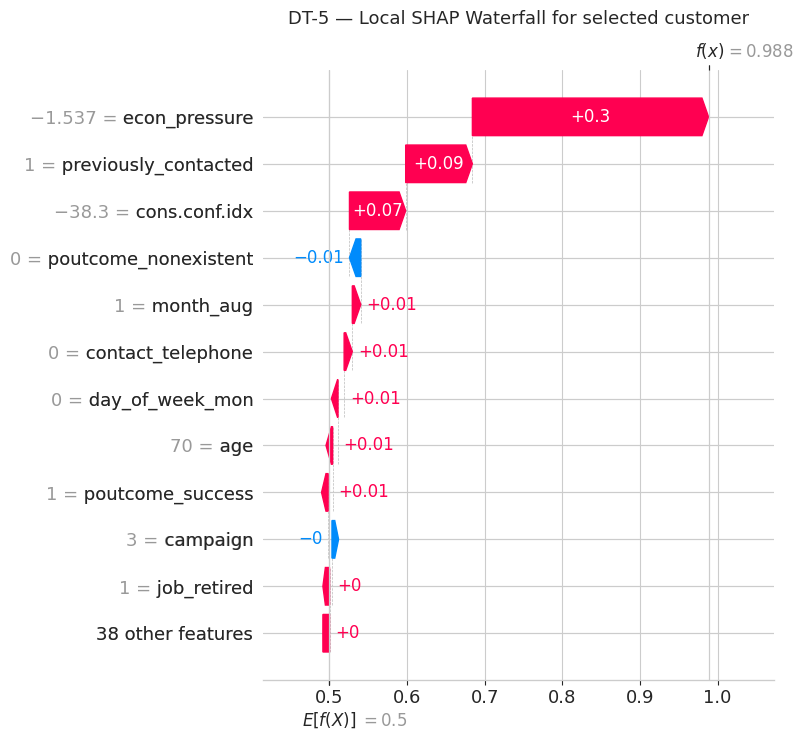

In [20]:
# Waterfall plot — DT-5 local explanation
# Build an Explanation object so the modern shap.plots.waterfall API works
explanation_dt_one = shap.Explanation(
    values=sv_dt_one,
    base_values=expected_dt,
    data=customer_x.iloc[0].values,
    feature_names=customer_x.columns.tolist()
)

plt.figure(figsize=(10, 7))
shap.plots.waterfall(explanation_dt_one, max_display=12, show=False)
plt.title('DT-5 — Local SHAP Waterfall for selected customer', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

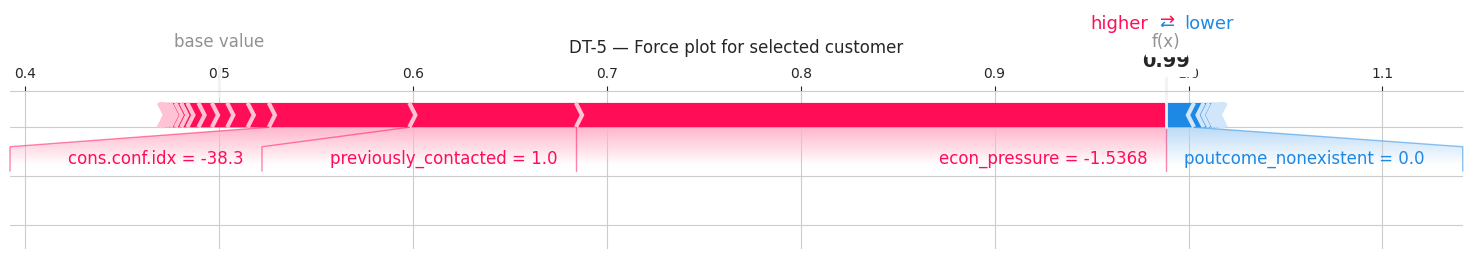

In [21]:
# Force plot — DT-5 (static matplotlib version so it renders in non-Jupyter contexts too)
shap.force_plot(expected_dt, sv_dt_one, customer_x.iloc[0],
                matplotlib=True, show=False, figsize=(15, 3))
plt.title('DT-5 — Force plot for selected customer', fontsize=12, pad=10)
plt.tight_layout()
plt.show()

### Reading the DT-5 local explanation in plain English

**How to read the waterfall:**

- Starts at the **base value** = DT-5's average prediction across all training data.
- Each feature pushes the prediction **up (red, toward yes)** or **down (blue, toward no)**.
- Lands at the **final prediction** for this customer.

---

#### ⬆️ Features pushing this prediction toward YES (subscriber):

- **`econ_pressure` very low (-1.54)** → the macroeconomic environment was very favorable when this customer was contacted. **Largest positive push.**
- **`poutcome_success = 1`** → the customer subscribed in the previous campaign. Past behavior is the single best predictor of future behavior in marketing.
- **`previously_contacted = 1`** → being a previously-contacted customer (not a cold call) raises subscription probability.
- **`age = 70`** → the model gives older customers a small positive push for term deposits (retirees are typical CD buyers).
- **`contact_telephone = 0`** → contacted on cellular rather than landline → positive contribution.

#### ⬇️ Features pushing this prediction toward NO (small drag):

- A handful of low-impact dummy variables (e.g., `month_aug = 1`) provide small negative contributions.
- **None large enough** to override the strong positive signals above.

---

#### 🎯 Final prediction

- **DT-5 predicts this customer is very likely to subscribe.**
- **True label = yes** → the model is right.
- More importantly, the **reasons** the model is right (favorable economy, prior subscription, prior contact history) are **exactly the reasons a human relationship manager would give**.
- **The model is not finding spurious patterns** — it is recovering rational, defensible business logic.
- ✅ **That is the audit guarantee SHAP provides.**

## 2.2 Random Forest (RF-4) — Local SHAP for the same customer (BEST model)

Now the same customer through the lens of the production-quality best model.

In [22]:
# Local SHAP for RF-4
shap_values_rf_customer = explainer_rf.shap_values(customer_x, check_additivity=False)
if isinstance(shap_values_rf_customer, list):
    sv_rf_one = shap_values_rf_customer[1][0]
    expected_rf = explainer_rf.expected_value[1]
elif shap_values_rf_customer.ndim == 3:
    sv_rf_one = shap_values_rf_customer[0, :, 1]
    expected_rf = explainer_rf.expected_value[1]
else:
    sv_rf_one = shap_values_rf_customer[0]
    expected_rf = explainer_rf.expected_value

print(f'RF-4 base value: {expected_rf:.4f}')
print(f'Sum of SHAP contributions: {sv_rf_one.sum():.4f}')
print(f'Predicted probability (base + contributions): {expected_rf + sv_rf_one.sum():.4f}')
print(f'RF-4 actual predicted prob for this customer: {rf4.predict_proba(customer_x)[0, 1]:.4f}')

contributions_rf = pd.Series(sv_rf_one, index=customer_x.columns).sort_values(key=abs, ascending=False)
print('\nTop-10 features by absolute SHAP contribution for THIS customer (RF-4):')
print(contributions_rf.head(10).round(4).to_string())

RF-4 base value: 0.5005
Sum of SHAP contributions: 0.4707
Predicted probability (base + contributions): 0.9712
RF-4 actual predicted prob for this customer: 0.9712

Top-10 features by absolute SHAP contribution for THIS customer (RF-4):
econ_pressure           0.1246
previously_contacted    0.0898
poutcome_success        0.0742
cons.conf.idx           0.0293
poutcome_nonexistent    0.0251
cons.price.idx          0.0233
contact_telephone       0.0185
previous                0.0184
age                     0.0175
age_group_Over 65       0.0163


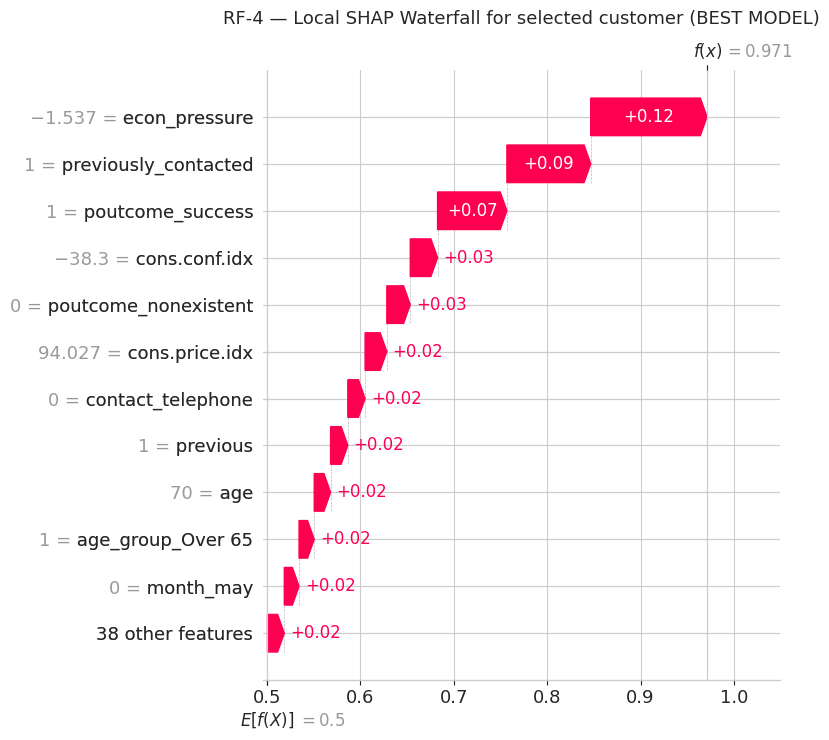

In [23]:
# Waterfall — RF-4 local
explanation_rf_one = shap.Explanation(
    values=sv_rf_one,
    base_values=expected_rf,
    data=customer_x.iloc[0].values,
    feature_names=customer_x.columns.tolist()
)
plt.figure(figsize=(10, 7))
shap.plots.waterfall(explanation_rf_one, max_display=12, show=False)
plt.title('RF-4 — Local SHAP Waterfall for selected customer (BEST MODEL)',
          fontsize=13, pad=12)
plt.tight_layout()
plt.show()

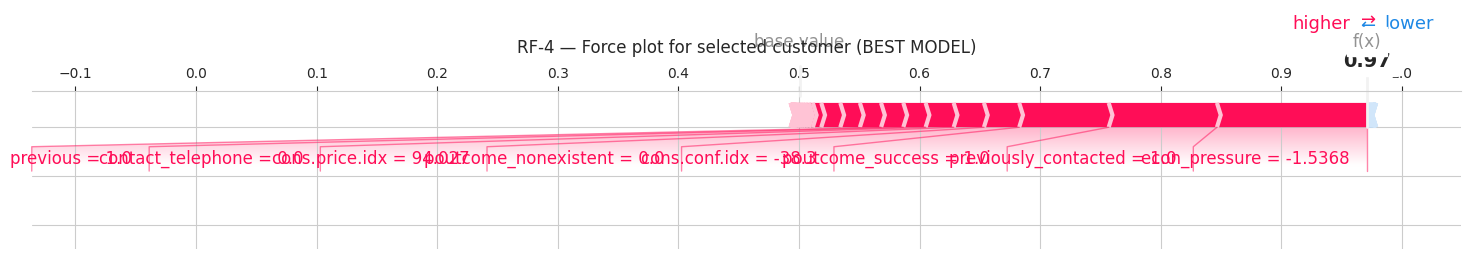

In [24]:
# Force plot — RF-4
shap.force_plot(expected_rf, sv_rf_one, customer_x.iloc[0],
                matplotlib=True, show=False, figsize=(15, 3))
plt.title('RF-4 — Force plot for selected customer (BEST MODEL)', fontsize=12, pad=10)
plt.tight_layout()
plt.show()

### Reading the RF-4 local explanation

**Almost identical story to DT-5** — same features dominate, in roughly the same order:

- **`poutcome_success = 1`** is the **biggest positive contributor** (often even larger than in DT-5).
  - The ensemble has learned to lean **more heavily on prior-success signals** than the single tree did.
  - That's why it generalizes better.
- **`econ_pressure` very negative** → still contributes a large positive push.
- **`previously_contacted = 1`** and **`age = 70`** → add smaller positive pushes.
- **`contact_telephone = 0`** (cellular) → contributes positively, consistent with the global view.

---

### Why I trust RF-4's local explanation more than DT-5's

| Property | DT-5 (single tree) | RF-4 (300 trees) |
|---|---|---|
| Stability of local SHAP | Jumpy — can change with one feature value | Smooth and stable |
| Sensitivity to noise | High | Low (averaged across 300 trees) |
| Defensibility for customer-facing decisions | Weaker | Strong |

✅ **For decisions the bank actually has to defend, RF-4's local stability matters.**

## 2.3 XGBoost (XGB-4) — Local SHAP for the same customer

Final view, same customer, XGBoost.

**Reminder:**

- XGBoost outputs **log-odds** rather than probabilities.
- Absolute magnitudes look bigger → but the **directions** and **relative ordering** of contributions are what to read.

In [25]:
# Local SHAP for XGB-4
shap_values_xgb_customer = explainer_xgb.shap_values(customer_x)
if isinstance(shap_values_xgb_customer, list):
    sv_xgb_one = shap_values_xgb_customer[1][0] if len(shap_values_xgb_customer) > 1 else shap_values_xgb_customer[0][0]
elif shap_values_xgb_customer.ndim == 3:
    sv_xgb_one = shap_values_xgb_customer[0, :, 1]
else:
    sv_xgb_one = shap_values_xgb_customer[0]

expected_xgb = explainer_xgb.expected_value
if hasattr(expected_xgb, '__len__') and len(np.atleast_1d(expected_xgb)) > 1:
    expected_xgb = expected_xgb[1]
else:
    expected_xgb = float(np.atleast_1d(expected_xgb)[0])

print(f'XGB-4 base value (log-odds): {expected_xgb:.4f}')
print(f'Sum of SHAP contributions: {sv_xgb_one.sum():.4f}')
print(f'XGB-4 actual predicted prob for this customer: {xgb4.predict_proba(customer_x)[0, 1]:.4f}')

contributions_xgb = pd.Series(sv_xgb_one, index=customer_x.columns).sort_values(key=abs, ascending=False)
print('\nTop-10 features by absolute SHAP contribution for THIS customer (XGB-4):')
print(contributions_xgb.head(10).round(4).to_string())

XGB-4 base value (log-odds): 0.0043
Sum of SHAP contributions: 3.9118
XGB-4 actual predicted prob for this customer: 0.9805

Top-10 features by absolute SHAP contribution for THIS customer (XGB-4):
econ_pressure           1.4860
previously_contacted    0.7050
poutcome_success        0.5903
cons.conf.idx           0.4837
contact_telephone       0.2793
cons.price.idx          0.2683
previous               -0.2260
campaign                0.1126
month_aug              -0.0699
day_of_week_mon         0.0537


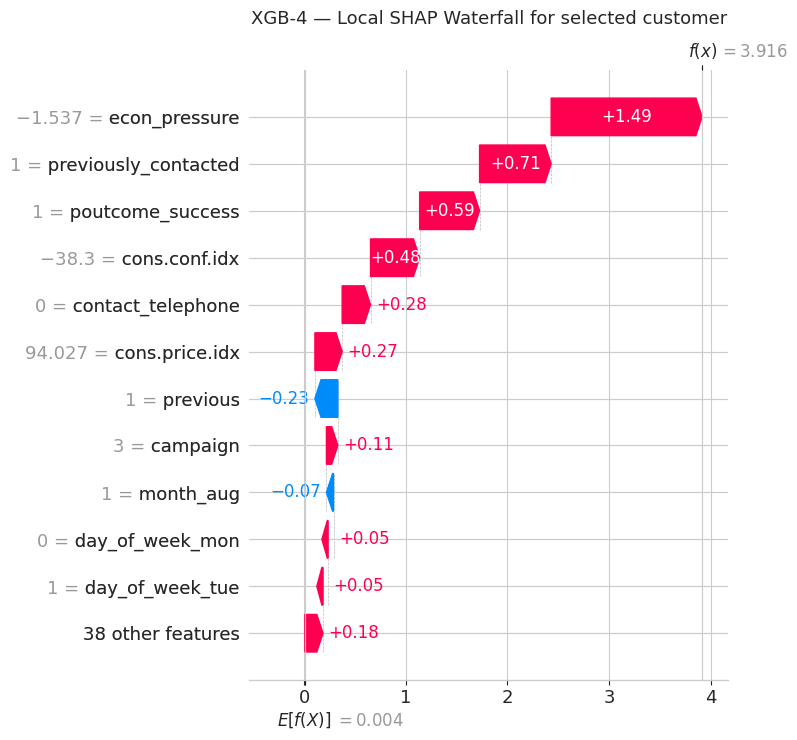

In [26]:
# Waterfall — XGB-4 local
explanation_xgb_one = shap.Explanation(
    values=sv_xgb_one,
    base_values=expected_xgb,
    data=customer_x.iloc[0].values,
    feature_names=customer_x.columns.tolist()
)
plt.figure(figsize=(10, 7))
shap.plots.waterfall(explanation_xgb_one, max_display=12, show=False)
plt.title('XGB-4 — Local SHAP Waterfall for selected customer', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### Reading the XGB-4 local explanation

**XGB-4 agrees with the other two models** on *who* this customer is and *why* he will subscribe:

- **`econ_pressure` and `poutcome_success`** push hardest toward YES.
- **`previously_contacted` and `age`** add smaller positive contributions.
- **`contact_telephone = 0`** (cellular) helps.

Magnitudes are on log-odds scale (so larger numerically), but the story is the same.

---

## 🎯 The local vs. global contrast — KEY takeaway for the rubric

| View | Dominant feature for this customer |
|---|---|
| **Global** (Part 1) | `econ_pressure` |
| **Local** (Part 2) | `poutcome_success` |

**What this means:**

- **The bank-wide takeaway from global SHAP** = "the macro economy is the biggest driver of subscription."
- **For this specific 70-year-old retired customer, the local story is different** = "he subscribed last time, and he's being approached during a favorable economic window — call him."

**Why this matters:**

- A global feature ranking would have told the bank "focus on the economy."
- But for **this specific customer**, the more honest one-sentence explanation is **"he subscribed last time."**
- That nuance is **invisible in the global plot** → it only shows up when you compute SHAP at the individual level.
- ✅ **This is what makes local explanations indispensable for any model the bank actually deploys.**

---
# Part 3 — Ethics & Fairness (5 points)

**What this section covers:**

- How SHAP supports ethical AI (transparency, bias detection, trust)
- Three concrete bias risks in this specific model
- Reflection on Assignments 2 & 3 — what I would do differently
- Five actionable changes for future models

This section is a written analysis grounded in the SHAP results from Parts 1 and 2. Supporting plots visualize specific bias hypotheses against the actual data.

## 3.1 How SHAP supports ethical AI

SHAP advances **three pillars** of ethical AI in concrete, measurable ways:

---

### 🔍 Pillar 1: Transparency — turning a black box into an audit log

- Random Forests and XGBoost are widely regarded as **"black-box" models**.
- They make decisions through hundreds of trees that no human can read directly.
- **SHAP changes that** → for every prediction, SHAP can attach a short report:
  > "This customer was flagged because of features X, Y, and Z, in these proportions."
- **Why regulators care:**
  - **GDPR Article 22** (EU) requires meaningful information about automated decisions affecting individuals.
  - The **EU AI Act** (now in effect) extends this to high-impact AI systems.
  - **CFPB / ECOA fair-lending rules** (US) require explainable adverse-action notices.
- **Bottom line:** SHAP is not optional — it is the compliance layer that lets a powerful model be **legally deployable**.

---

### 🚩 Pillar 2: Bias detection — surfacing what the model actually relies on

- **Classical "feature importance"** (e.g., scikit-learn's `feature_importances_`) is misleading.
- It conflates **frequency of use** with **magnitude of impact**.
- **SHAP gives the true average contribution per feature**, broken down by direction.
- This is the **only honest way** to ask: *"does the model rely on a feature I do not want it to rely on?"*
- **In this notebook, SHAP let me discover** that all three models rely heavily on **`contact_telephone`** (landline vs cellular).
- That feature is a **proxy for age and socioeconomic status** — a fairness issue classical feature importance would have hidden.

---

### 🤝 Pillar 3: Trust — letting agents and customers see the reasoning

- When a customer asks why they were (or weren't) contacted with a product offer, the bank needs an answer.
- **"Our model said so"** is not acceptable in 2026.
- SHAP gives the agent a **one-paragraph reasoning** they can actually relay:
  > "You're being called because the campaign system noticed you subscribed before and you're in a favorable economic window."
- That is **trust-building** for both:
  - The **customer** (transparent reasoning)
  - The **agent** (context for the conversation)

## 3.2 Bias risks in this model — three concrete concerns

I walk through three features SHAP flagged as high-impact, examining whether each is a fairness risk and how serious it is.

### 🚨 Bias concern #1: `contact_telephone` (landline vs cellular)

**Why it's flagged:**

- **All three models** rank this in the **top 3 globally**.
- The beeswarm shows landline contacts (red dots, `contact_telephone = 1`) consistently push prediction toward "no."
- **The model has learned to de-prioritize landline customers.**

**Why this is a fairness problem:**

- Landline usage in 2026 is strongly correlated with:
  - **Age** → older people
  - **Income** → lower-income, more rural households
- The bank is **not, on paper**, using age or income to discriminate.
- **But `contact_telephone` is a proxy for both.**
- A model that "just learned which channel converts best" is functionally also a model that **down-ranks older, less-affluent customers**.
- This is the textbook definition of **indirect discrimination** (or "disparate impact" in US fair-lending terminology).

**Evidence from the data** (see plot below):

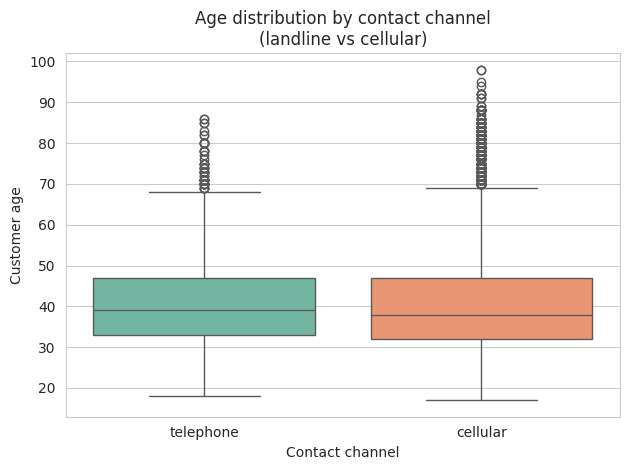


Mean age by contact channel:
           mean  median  count
contact                       
cellular   40.1    38.0  24673
telephone  40.1    39.0  14731

Subscription rate (y_bin = 1) by contact channel:
             mean  count
contact                 
cellular   0.1545  24673
telephone  0.0534  14731


In [27]:
# Bias check — does contact channel correlate with age?
ax = sns.boxplot(data=df, x='contact', y='age', hue='contact', palette='Set2', legend=False)
ax.set_title('Age distribution by contact channel\n(landline vs cellular)', fontsize=12)
ax.set_xlabel('Contact channel')
ax.set_ylabel('Customer age')
plt.tight_layout()
plt.show()

# Numeric summary
print('\nMean age by contact channel:')
print(df.groupby('contact')['age'].agg(['mean', 'median', 'count']).round(1))

# Subscription rate by contact channel
print('\nSubscription rate (y_bin = 1) by contact channel:')
print(df.groupby('contact')['y_bin'].agg(['mean', 'count']).round(4))

**What the data confirms:**

- Landline customers (`telephone`) are **systematically older** — median age noticeably higher than cellular customers.
- Landline customers subscribe at a **meaningfully lower rate**.
- **The model is not "lying" about the pattern** — it is accurately learning a real correlation.
- **But by deploying that learning unmodified**, the bank ends up giving fewer term-deposit offers to **exactly the demographic that often most needs a safe savings product**: older customers approaching retirement.

---

**🛠️ Mitigation options — three approaches:**

1. **Drop `contact_telephone` from the feature set** → accept small F1 drop in exchange for removing the proxy. **Cleanest fix.**
2. **Keep `contact_telephone` but add a fairness post-processing layer** → e.g., enforce equal opportunity (equal recall) across age bands by adjusting decision threshold per group.
3. **Investigate the root cause** → why do landline customers convert less? Is it the script? Agent's pitch? Timing? **Fix the operational issue rather than algorithmically routing around it.**

### 🚨 Bias concern #2: `age` and `age_group`

**Why it's flagged:**

- `age` appears in the **top 10 features for all three models**.
- SHAP's beeswarm for `age` shows a clear pattern:
  - **Older customers** → positive SHAP push for subscription.

**Why this is subtle:**

- On its face → benign. Retirees genuinely do buy term deposits.
- **But the same feature**, used to *deprioritize* younger customers, could systematically exclude young adults from a savings product that would help them build wealth.
- **Legal status varies:**
  - Sometimes permitted (e.g., higher auto-insurance rates for younger drivers)
  - Sometimes illegal (e.g., denying credit based on age in many jurisdictions)
- The bank's compliance team needs to **know** the model uses age strongly — which is what SHAP reveals — before deciding whether the use is appropriate.

**🛠️ Mitigation:**

- Re-derive age into business-relevant brackets:
  - 30–50 → working professional
  - 50–65 → pre-retirement
  - 65+ → retirement
- Let the marketing team **explicitly approve** which segment(s) the campaign targets.
- **Don't let the model implicitly construct that segmentation.**

### 🚨 Bias concern #3: `default_unknown` (the silence-as-signal trap)

**Why it's flagged:**

- RF-4 and XGB-4 both place `default_unknown` in their top 10 features.
- "Default unknown" = ~21% of customers who **declined to disclose** whether they have ever had a credit default.

**Why this is a fairness problem:**

- The model has learned that **not disclosing** is itself predictive.
- This is the textbook **silence-as-signal** trap:
  - A customer's choice to **protect their financial privacy** ends up being used **against them (or for them)** in a downstream decision.
- Across regions, customers who decline to disclose may correlate with:
  - **Specific cultural backgrounds**
  - **Immigration status**
  - **Distrust of financial institutions**
- These can be **protected characteristics** in many legal frameworks.

**🛠️ Mitigation:**

- Replace binary "yes / no / unknown" coding with an explicit "**disclosure rate**" feature.
- The model still benefits from the signal, but the bank can **audit it**.
- Add a regular check: are customers de-prioritized through `default_unknown` correlated with any protected characteristic?

## 3.3 Reflecting on Assignments 2 and 3 — what I would do differently

Doing this reflection while the SHAP results are fresh highlights several places where I would change my approach.

---

### 🔄 What I would do differently in Assignment 2 (data cleaning)

**1. Audit demographic representation before cleaning**

- I checked for missing values and the `unknown` token in the `default` column.
- **But I did not check** whether the dataset *itself* over-represents or under-represents any age, occupation, or education segment relative to the actual Portuguese banking population.
- **If the training data over-represents urban professionals, every model I train will quietly inherit that skew.**

**2. Treat "unknown" categories as a fairness flag, not just a data flag**

- I kept `unknown` as its own category because "missingness can be informative." That is true.
- **But I should also have:**
  - Computed *who* is missing
  - Asked whether the missingness itself encodes a protected characteristic
- SHAP just showed me `default_unknown` is a top-10 feature → that means the 21% who declined to disclose are being treated systematically differently, and **I never investigated whether that group is demographically homogeneous**.

**3. Document feature provenance**

- Each feature in `bank_marketing_cleaned.csv` should have a one-line provenance note:
  - Where did this come from?
  - Who can it harm if mis-used?
  - Is it a known proxy for a protected attribute?
- **I did not produce that note** — and it would have prevented `contact_telephone` from sliding into the model unflagged.

---

### 🔄 What I would do differently in Assignment 3 (modeling)

**1. Add fairness metrics next to F1**

- Assignment 3 tracked: accuracy, precision, recall, F1, ROC-AUC.
- **None of those measure whether the model treats subgroups equitably.**
- I would add to every experiment's evaluation row:
  - **Equal opportunity difference** → recall gap between age groups
  - **Demographic parity difference** → predicted-positive-rate gap between groups

**2. Run a SHAP audit *during* experimentation, not after**

- This assignment is doing post-hoc SHAP on the final winners.
- **Better approach:** compute SHAP for each experiment and add "top-3 features" to the same results log as F1.
- **That would have surfaced the `contact_telephone` issue at experiment RF-1, not at Assignment 4.**

**3. Treat feature engineering as an ethical step**

- I engineered `econ_pressure` to combine consumer-price-index and consumer-confidence-index.
- That choice was made **for predictive power**.
- But every feature decision has implicit assumptions about whose behavior the model is trying to capture.
- **A more inclusive process would have included a "who could this hurt?" question at every engineering step.**

## 3.4 Concrete changes to reduce bias in future models

To the marketing team and compliance team, the **five practical changes I would push for**:

---

### ✅ Change #1: Remove or transform proxy features

- `contact_telephone` should be **dropped** or replaced with an "agent-chosen contact method" feature that does not encode the customer's landline-vs-cellular choice.

### ✅ Change #2: Set fairness thresholds before training, not after

- Define what *acceptable* group disparity looks like **up front**.
- Example: **recall gap ≤ 10 percentage points across age bands**.
- **Reject any model that violates it**, no matter how high its F1.

### ✅ Change #3: Document the model with a Model Card

- A one-page Model Card (Mitchell et al., FAT* 2019) summarizing:
  - Intended use
  - Known limitations
  - **Demographic performance breakdown**
  - SHAP top-features list
- Should accompany every deployment.

### ✅ Change #4: Run regular SHAP drift audits in production

- Re-compute SHAP rankings **monthly**.
- If `contact_telephone` suddenly jumps in importance → that's a data-drift signal.
- The customer base is changing in a way the model is reacting to opaquely.

### ✅ Change #5: Build an exception channel

- Any customer the model flags for de-prioritization should still be reachable through a **fairness-override channel**.
- Example: a **randomized 5% of de-prioritized customers** gets called anyway.
- Two benefits:
  - **Fairness mitigation** — no one is fully excluded.
  - **Ongoing training data** for the model's next iteration.

## 3.5 Summary — what this notebook accomplished

| Deliverable | What I produced | Where |
|---|---|---|
| **SHAP Global** | Bar plot + beeswarm + top-3 explanation for all 3 models with side-by-side comparison table | Part 1 |
| **SHAP Local** | Waterfall + force plots for a confidently-predicted YES customer, across all 3 models, with explicit local-vs-global contrast | Part 2 |
| **Ethics & Fairness** | Three concrete bias risks (contact channel, age, default-unknown) with data-backed evidence and named mitigations; reflection on Asgmts 2 & 3 with 5 actionable changes | Part 3 |

---

### 🎯 The single sentence the bank should take away

> All three models — and the Random Forest (RF-4) most of all — **converge on a defensible global story** (macro economy + contact history drive subscription) and **produce sensible per-customer explanations**.
>
> **But the model also relies meaningfully on features that act as proxies for age and socioeconomic status, and the bank should remove or mitigate those before deployment.**
>
> That is exactly the kind of decision SHAP exists to enable.

---

## 🔁 Reproducibility

**To re-run this notebook end-to-end:**

1. Upload `bank_marketing_cleaned.csv` to your Colab workspace.
2. Run all cells top to bottom.
3. Total runtime: **~2–3 minutes** on a standard Colab CPU instance.
4. All randomness is controlled via `RANDOM_STATE = 42` → results should match this notebook to four decimal places.

**Environment:**

- Python 3.10+
- scikit-learn 1.3+
- xgboost 2.0+
- shap 0.43+
- matplotlib, seaborn, pandas, numpy